In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


In [2]:
train = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv')
test = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv')
sample = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv')

In [3]:
train.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3


In [4]:
x = train.drop(['price_tier'],axis=1)
y = train['price_tier']

In [5]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("submission shape:", sample.shape)

Train shape: (279746, 60)
Test shape: (114538, 59)
submission shape: (114538, 2)


In [6]:
print("\nTraining data types:")
print(train.dtypes)

print("\nTest data types:")
print(test.dtypes)

print("\nColumns only in train:")
print(set(train.columns) - set(test.columns))

print("\nColumns only in test:")
print(set(test.columns) - set(train.columns))



Training data types:
space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
facilities                       object
snapshot_start_date              object
snapshot_end_date                object
min_term_days     

price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64
price_tier
1    23.910619
2    29.144295
3    21.747943
4    25.197143
Name: proportion, dtype: float64


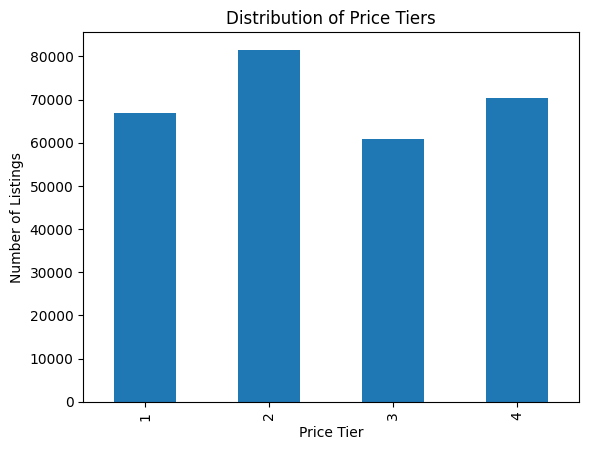

In [7]:
import matplotlib.pyplot as plt

# Count each price tier
print(train["price_tier"].value_counts().sort_index())

# Calculate percentage of each price tier
print(train["price_tier"].value_counts(normalize=True).sort_index() * 100)

# Plot the distribution
train["price_tier"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Price Tiers")
plt.xlabel("Price Tier")
plt.ylabel("Number of Listings")
plt.show()

In [8]:
# Missing values in training data
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values in training data:")
print(missing)

# Percentage of missing values
print("\nMissing percentage:")
print((train.isnull().mean() * 100).round(2).loc[lambda x: x > 0])

# Missing values in test data
print("\nMissing values in test data:")
print(test.isnull().sum()[test.isnull().sum() > 0])

Missing values in training data:
borough                         214451
score_value                      54246
score_access                     54245
score_onboarding                 54243
score_accuracy                   54242
score_support                    54241
last_review_date                 54240
score_condition                  54240
first_review_date                54240
reviews_per_month                54240
score_overall                    54236
zones                            48414
utility_rooms                    29899
workstations                     18783
operator_active_years              606
operator_active_months             606
operator_has_avatar                604
operator_id_verified               604
operator_platform_age_years        604
operator_ref                       604
operator_platform_age_months       604
operator_certified                 604
operator_portfolio_size            604
bookable                            97
min_term_days                  

price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64
price_tier
1    23.910619
2    29.144295
3    21.747943
4    25.197143
Name: proportion, dtype: float64


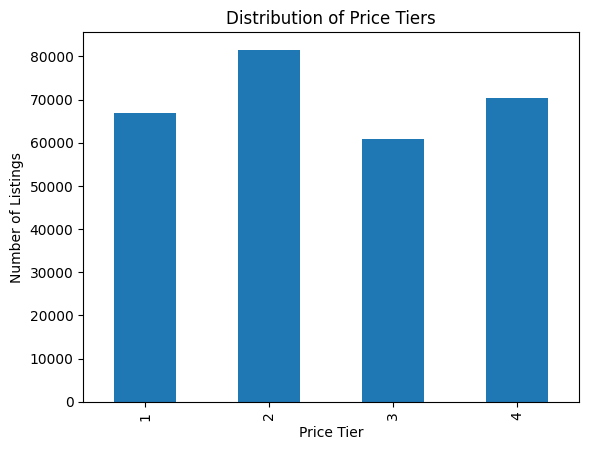

In [9]:
import matplotlib.pyplot as plt

# Count each price tier
print(train["price_tier"].value_counts().sort_index())

# Calculate percentage of each price tier
print(train["price_tier"].value_counts(normalize=True).sort_index() * 100)

# Plot the distribution
train["price_tier"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Price Tiers")
plt.xlabel("Price Tier")
plt.ylabel("Number of Listings")
plt.show()

In [10]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test:", test.duplicated().sum())

print("Duplicate space_id in train:", train["space_id"].duplicated().sum())
print("Duplicate space_id in test:", test["space_id"].duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0
Duplicate space_id in train: 0
Duplicate space_id in test: 0


In [11]:

num = train.select_dtypes(include="number")

print(num.describe().round(2))

        space_id  operator_platform_age_years  operator_platform_age_months  \
count  279746.00                    279142.00                     279142.00   
mean   139872.50                         6.79                          5.45   
std     80755.86                         4.19                          3.49   
min         0.00                         0.00                          0.00   
25%     69936.25                         3.00                          2.00   
50%    139872.50                         7.00                          5.00   
75%    209808.75                        10.00                          9.00   
max    279745.00                        17.00                         11.00   

       operator_active_years  operator_active_months  operator_portfolio_size  \
count              279140.00               279140.00                279142.00   
mean                    5.08                    5.30                    49.47   
std                     4.04                 

## 2. Plot distributions

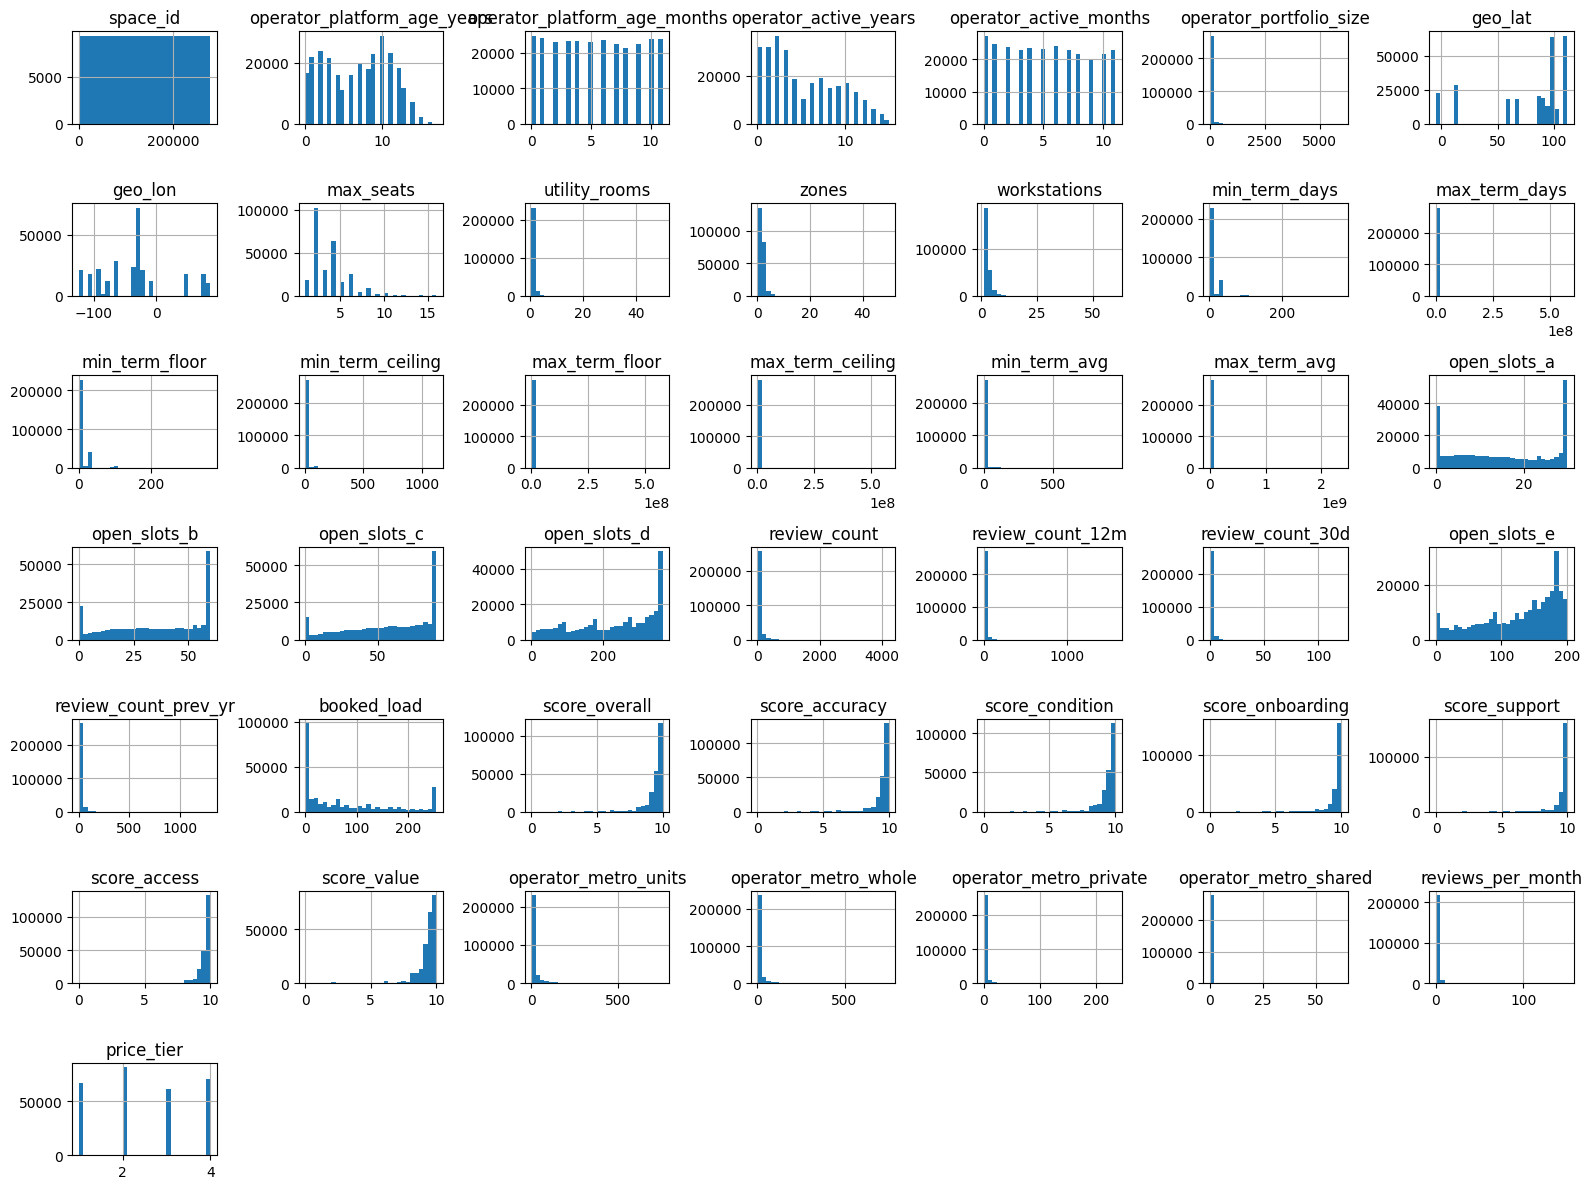

In [12]:
num.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

## 3. Check outliers using IQR

In [13]:
Q1 = num.quantile(0.25)
Q3 = num.quantile(0.75)
IQR = Q3 - Q1

outliers = ((num < Q1 - 1.5 * IQR) |
            (num > Q3 + 1.5 * IQR)).sum()

print(outliers.sort_values(ascending=False))

min_term_ceiling                57708
min_term_avg                    57207
min_term_days                   53091
min_term_floor                  53091
geo_lat                         51250
operator_metro_private          49759
operator_metro_whole            44953
operator_metro_units            40157
operator_portfolio_size         39784
review_count_30d                38748
geo_lon                         29033
review_count                    28455
review_count_prev_yr            27748
review_count_12m                19533
score_support                   19235
utility_rooms                   18474
max_seats                       18102
score_value                     16445
score_onboarding                16179
score_overall                   15154
score_condition                 14673
score_accuracy                  14571
score_access                    12564
zones                           12099
reviews_per_month                8769
workstations                     5437
operator_met

## 1. Check categorical columns

In [14]:
cat_cols = train.select_dtypes(include="object").columns

for col in cat_cols:
    print("\n", col)
    print(train[col].value_counts().head(10))


 operator_ref
operator_ref
Bessstu       1467
Zianovath     1160
Nalsto        1088
Dessselra     1030
Stianianlo     949
Klynfova       946
Sinnovara      801
Zelten         773
Snyniv         750
Hynbalrn       732
Name: count, dtype: int64

 operator_class
operator_class
unverified_operator     127473
independent_operator    111887
managed_operator         40386
Name: count, dtype: int64

 operator_certified
operator_certified
f    180235
t     98907
Name: count, dtype: int64

 operator_has_avatar
operator_has_avatar
t    267462
f     11680
Name: count, dtype: int64

 operator_id_verified
operator_id_verified
t    275236
f      3906
Name: count, dtype: int64

 zone
zone
ZN-0923    10990
ZN-0779     9377
ZN-0948     8601
ZN-0536     4658
ZN-1039     3667
ZN-0454     3621
ZN-0812     3020
ZN-0315     2881
ZN-1020     2697
ZN-0973     2673
Name: count, dtype: int64

 borough
borough
BRG-18    10670
BRG-30     9220
BRG-22     8773
BRG-14     5386
BRG-10     4460
BRG-45     4152
BRG-41 

## 2. Check how many unique values each column has

In [15]:
print(train[cat_cols].nunique().sort_values(ascending=False))


facilities              251649
operator_ref             41903
first_review_date         5342
last_review_date          3287
zone                      1380
snapshot_end_date          384
snapshot_start_date        383
space_class                131
borough                     55
metro                       16
access_type                  4
compliance_status            4
operator_class               3
operator_has_avatar          2
operator_certified           2
operator_id_verified         2
bookable                     2
dtype: int64


In [16]:
from sklearn.dummy import DummyClassifier

In [17]:
dummy_model = DummyClassifier(strategy= 'constant' , constant = 1)
dummy_model.fit(x,y)

DummyClassifier(constant=1, strategy='constant')

In [18]:
dummy_prediction = dummy_model.predict(test)

In [19]:
dummy_prediction

array([1, 1, 1, ..., 1, 1, 1])

In [20]:
sample.head()

,ID,price_tier
0,0,2
1,1,2
2,2,2
3,3,2
4,4,2


In [21]:
sample['price_tier'] = dummy_prediction

In [22]:
sample.head()

,ID,price_tier
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1


In [23]:
sample.to_csv("submission.csv",index=False)